<div style="text-align: center; font-style: italic; font-size: 18px">Water Resources Management</div>
<div></div>
<div style="text-align: center">Supplementary Information of</div>
<div style="text-align: center; font-weight: bold; font-size: 24px">Data-Driven Leak Localization Modeling for Optimal Sensor Placement</div>

---

Maria Gloria Di Chiano<sup>1*</sup>, Dennis Zanutto<sup>2,3</sup>, Gianfranco Becciu<sup>1</sup>, Dragan Savić<sup>3,4</sup>

<sup>1</sup>D.I.C.A. Politecnico di Milano, 20133 Milano, Italy

<sup>2</sup>D.E.I.B, Politecnico di Milano, 20133, Milano, Italy

<sup>3</sup>KWR Water Research Institute, Nieuwegein, 3430 BB, the Netherlands

<sup>4</sup>Centre for Water Systems, University of Exeter, Exeter, EX4 4QF, United Kingdom


## Content of this File

- Text S5.1
- Text S5.2

## Introduction
This notebook tests the impact of the leak scenario database on the optimal sensor placement problem. The question is wheter using a single leak magnitude or testing leaks of different magnitudes affects the OSP problem and the leak signatrue matrix (LSM) reconstruction methods.

In [1]:
# Imports
from wdn_osp_ll.sensor_placement_optimization import load_or_compute
from wdn_osp_ll.visualization import (
    plot_pareto_front_nsensors_msa,
    plot_hypervolume_bar,
    plot_hypervolume_trajectory,
)

## Text S5

## Text S5.1 - Impact of the LSM Reconstruction Method

Until now, we compared different configurations of the OSP problem using the same LSM reconstruction method. In this section, we compare the best configuration of each reconstruction method.

In [2]:
best_boatwright_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "boatwright",
                    "args": {
                        "metric": "length",
                        "directed": False,
                        "exponent": None,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

best_boatwright_res = load_or_compute(config=best_boatwright_cfg)

In [3]:
best_alves_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "alves",
                    "args": {
                        "directed": False,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

best_alves_res = load_or_compute(config=best_alves_cfg)

In [4]:
best_topo_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "clustering",
                    "args": {
                        "metric": "length",
                        "directed": False,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

best_topo_res = load_or_compute(config=best_topo_cfg)

Starting optimisation...
[2026-11-06 14:34:21] generation      0 | best hypervolume: 195.838710 | median: 146.032258
[2026-11-06 14:34:23] generation     10 | best hypervolume: 333.258065 | median: 327.645161
[2026-11-06 14:34:23] generation     20 | best hypervolume: 340.096774 | median: 335.193548
[2026-11-06 14:34:24] generation     30 | best hypervolume: 341.322581 | median: 337.596774
[2026-11-06 14:34:24] generation     40 | best hypervolume: 341.709677 | median: 338.193548
[2026-11-06 14:34:24] generation     50 | best hypervolume: 341.838710 | median: 338.354839
[2026-11-06 14:34:24] generation     60 | best hypervolume: 341.838710 | median: 338.516129
[2026-11-06 14:34:24] generation     70 | best hypervolume: 341.838710 | median: 339.322581
[2026-11-06 14:34:25] generation     80 | best hypervolume: 341.967742 | median: 339.354839
[2026-11-06 14:34:25] generation     90 | best hypervolume: 342.806452 | median: 339.516129
[2026-11-06 14:34:25] generation    100 | best hypervol

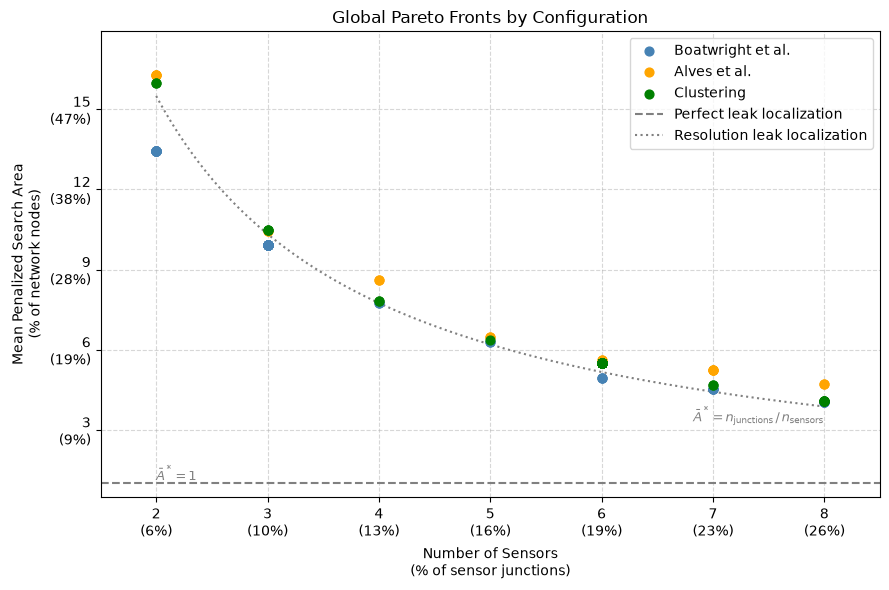

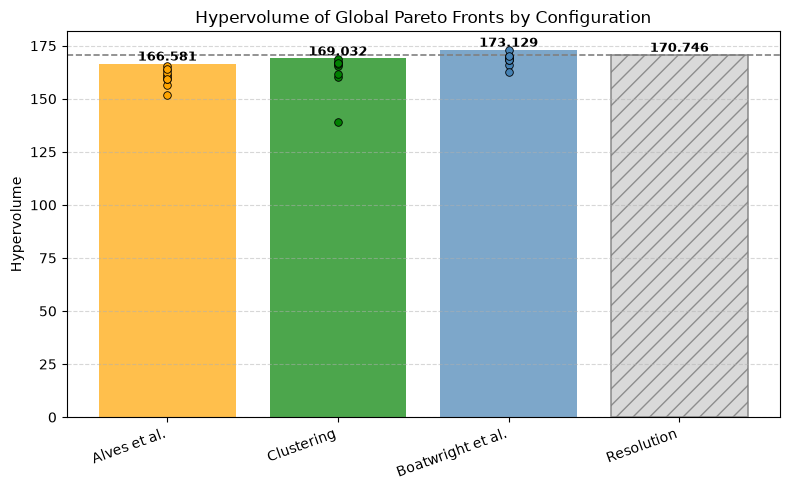

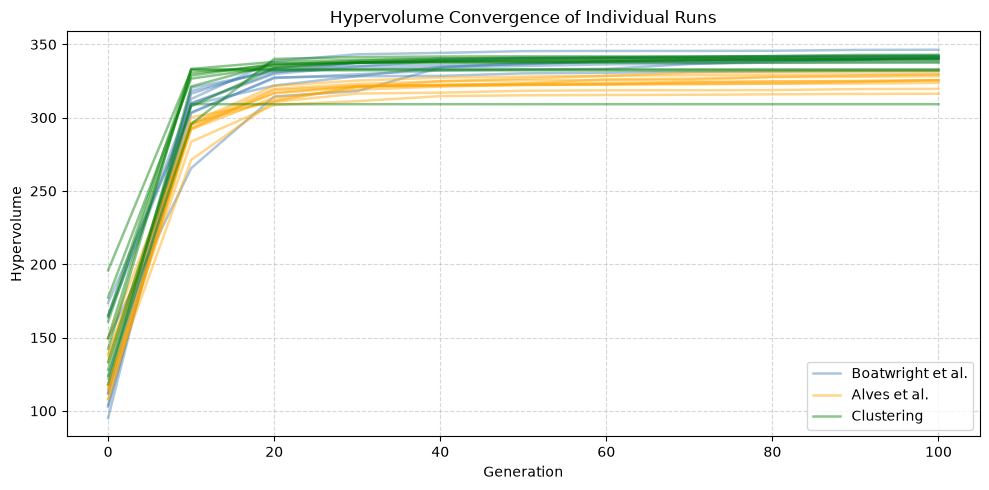

In [5]:
results = [best_boatwright_res, best_alves_res, best_topo_res]
labels = ["Boatwright et al.", "Alves et al.", "Clustering"]
colors = ["steelblue", "orange", "green", "purple"]

fig, ax = plot_pareto_front_nsensors_msa(results, labels, colors)
fig, ax = plot_hypervolume_bar(results, labels, colors)
fig, ax = plot_hypervolume_trajectory(results, labels, colors)

**Results.** The Boatwright reconstruction method outperforms the other methods and even surpasses the resolution curve (nominal leak localization performance for a given number of sensors).
However, the margin is small, especially over the clustering approach.These results should be reviewed on different networks.

### S5.2 - Impact of the Leak Magnitude

This section compares the experiments of Section S5.1 with the same configurations but on a database of leaks which contains leak of different magnitudes at each junction.

The goal is to observe wheter leak magnitude impacts the reconstruction methods.

In [6]:
best_boatwright_multimag_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": None,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "boatwright",
                    "args": {
                        "metric": "length",
                        "directed": False,
                        "exponent": None,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

best_boatwright_multimag_res = load_or_compute(config=best_boatwright_multimag_cfg)

In [7]:
best_alves_multimag_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": None,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "alves",
                    "args": {
                        "directed": False,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

best_alves_multimag_res = load_or_compute(config=best_alves_multimag_cfg)

In [8]:
best_topo_multimag_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": None,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "clustering",
                    "args": {
                        "metric": "length",
                        "directed": False,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

best_topo_multimag_res = load_or_compute(config=best_topo_multimag_cfg)

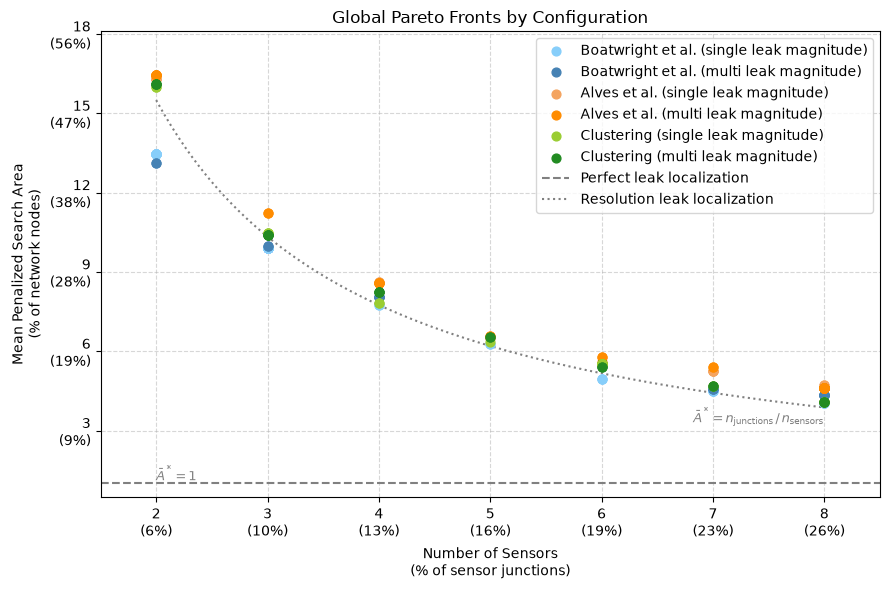

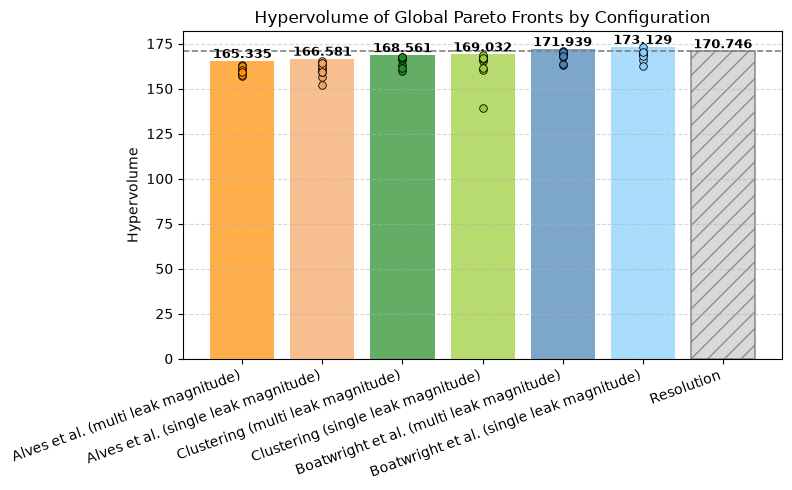

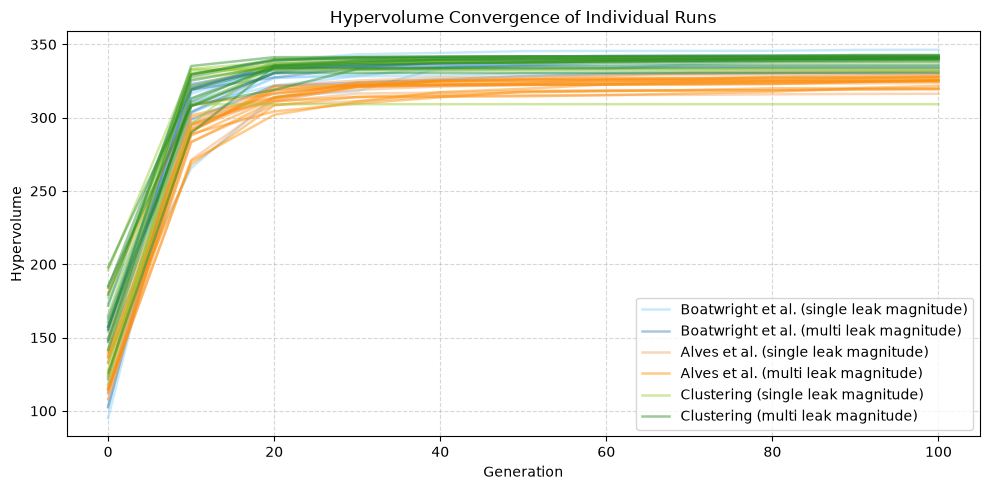

In [9]:
results = [
    best_boatwright_res, best_boatwright_multimag_res,
    best_alves_res, best_alves_multimag_res,
    best_topo_res, best_topo_multimag_res
]
labels = [
    "Boatwright et al. (single leak magnitude)", "Boatwright et al. (multi leak magnitude)",
    "Alves et al. (single leak magnitude)", "Alves et al. (multi leak magnitude)",
    "Clustering (single leak magnitude)", "Clustering (multi leak magnitude)",
]
colors = [
    "lightskyblue", "steelblue",
    "sandybrown", "darkorange",
    "yellowgreen", "forestgreen",
]

fig, ax = plot_pareto_front_nsensors_msa(results, labels, colors)
fig, ax = plot_hypervolume_bar(results, labels, colors)
fig, ax = plot_hypervolume_trajectory(results, labels, colors)

**Results.** The presence of leaks of different magnitudes in the same database marginally affects the reconstruction methods, thereby suggesting that they are pretty robust to the leak magnitude variations. This likely depends on the fact that the LL technique determines the search area using a relative threshold with respect to the highest pressure drop measured by any sensor. Thus, if the pressure drops induced by the leak magnitude variation are minimal or affect uniformly all nodes, this will not affect the reconstruction methods or the overall OSP procedure.